## Preparación del entorno

Ejecuta primero la siguiente celda para instalar las bibliotecas utilizadas en esta práctica. Usa `%pip` para instalar los paquetes en el Python asociado al kernel activo de este notebook.

**Nota:** la instalación requiere conexión a Internet y puede tardar varios minutos, especialmente por TensorFlow. 

In [2]:
#%pip install --upgrade pip
%pip install numpy matplotlib 
#tensorflow

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ----------------------- ---------------- 5.5/9.3 MB 25.7 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 24.8 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 24.8 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 11.2 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 9.0 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   --------------------------------- ------ 6.0/7.3 MB 28.4 MB/s eta 0:00:01
   -------------------------------------- - 7.1/7.3 MB 29.1 MB/s eta 0:00:01
   ---------------------------------------- 7.3/7.3 MB 13.6 MB/s  0:00:00
Usin

# Práctica: construcción y entrenamiento de una red neuronal con MNIST

**Objetivo:** construir paso a paso una red neuronal que clasifique imágenes de dígitos manuscritos del 0 al 9 con Python, TensorFlow y Keras.

## Descripción del problema

Una computadora recibe imágenes de números escritos a mano. Aunque representan los mismos diez dígitos, la escritura varía entre personas: cambia la forma, el tamaño, la inclinación y el grosor de los trazos. El reto es entrenar un modelo que identifique el dígito en imágenes que no utilizó para aprender.

## Indicaciones

1. Lee cada sección antes de ejecutar la celda de código que aparece después.
2. Ejecuta las celdas en orden, de arriba hacia abajo.
3. Observa las salidas y responde las preguntas de análisis al final.

**Producto esperado:** notebook ejecutado con visualización de datos, arquitectura, entrenamiento y evaluación.


## 1. Importar las bibliotecas

Importaremos las herramientas necesarias:
- **NumPy:** operaciones con arreglos numéricos.
- **Matplotlib:** visualización de imágenes y gráficas.
- **TensorFlow/Keras:** definición, entrenamiento y evaluación de la red neuronal.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)


NumPy: 2.4.6
TensorFlow: 2.21.0


## 2. Cargar el conjunto de datos MNIST

MNIST contiene imágenes de dígitos manuscritos en escala de grises. Keras proporciona dos grupos: **entrenamiento**, utilizado para aprender, y **prueba**, reservado para la evaluación final. Cada imagen mide 28 × 28 píxeles y su etiqueta indica el dígito correcto, de 0 a 9.


In [4]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Imágenes de entrenamiento:", x_train.shape)
print("Etiquetas de entrenamiento:", y_train.shape)
print("Imágenes de prueba:", x_test.shape)
print("Etiquetas de prueba:", y_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Imágenes de entrenamiento: (60000, 28, 28)
Etiquetas de entrenamiento: (60000,)
Imágenes de prueba: (10000, 28, 28)
Etiquetas de prueba: (10000,)


## 3. Inspeccionar etiquetas e imágenes

`y_train[:10]` muestra las primeras diez etiquetas. Pueden repetirse; no es necesario que aparezca cada dígito una sola vez. Después, `imshow` mostrará las matrices de píxeles y sus etiquetas.


Primeras diez etiquetas: [5 0 4 1 9 2 1 3 1 4]


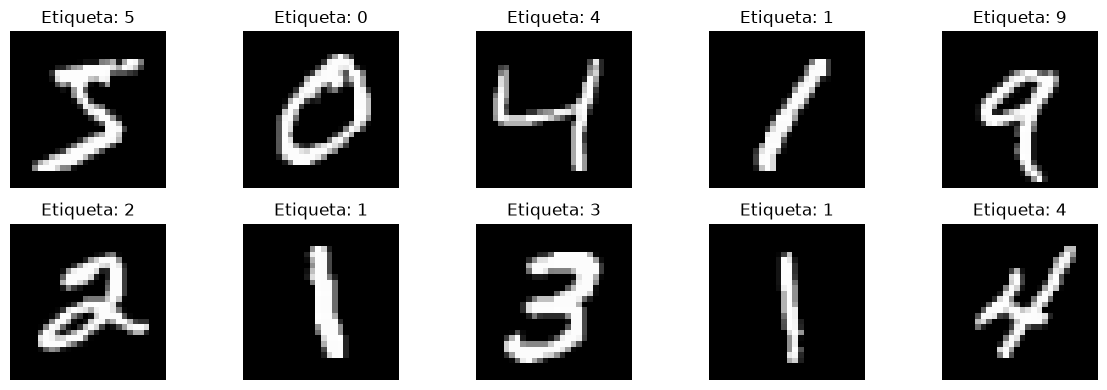

In [5]:
print("Primeras diez etiquetas:", y_train[:10])

plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Etiqueta: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


## 4. Normalizar los píxeles

Los píxeles originales toman valores de 0 a 255. Dividirlos entre 255 los convierte al intervalo de 0 a 1, una escala conveniente para el entrenamiento. La normalización no cambia el número de imágenes ni sus etiquetas; guardamos los resultados en variables nuevas.


In [6]:
x_train_norm = x_train.astype("float32") / 255.0
x_test_norm = x_test.astype("float32") / 255.0

print("Valor mínimo:", x_train_norm.min())
print("Valor máximo:", x_train_norm.max())
print("Forma de entrenamiento:", x_train_norm.shape)
print("Forma de prueba:", x_test_norm.shape)


Valor mínimo: 0.0
Valor máximo: 1.0
Forma de entrenamiento: (60000, 28, 28)
Forma de prueba: (10000, 28, 28)


## 5. Definir la arquitectura de la red neuronal

Usaremos `tf.keras.Sequential` para organizar las capas en secuencia:
1. **`Input(shape=(28, 28))`:** declara la forma de cada imagen.
2. **`Flatten()`:** convierte la matriz de 28 × 28 en un vector de 784 valores; cambia la forma, no aprende parámetros.
3. **`Dense(128, activation="relu")`:** crea una capa totalmente conectada con 128 neuronas. ReLU introduce no linealidad.
4. **`Dense(10, activation="softmax")`:** produce diez probabilidades, una por cada clase del 0 al 9.

En esta etapa definimos la estructura; la red todavía no ha aprendido a reconocer dígitos.
Importante: Python es el lenguaje de programación, TensorFlow es la plataforma de aprendizaje automático y Keras proporciona una interfaz sencilla para definir y utilizar redes neuronales.


In [7]:
modelo = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

modelo.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Configurar el aprendizaje

Antes de entrenar indicamos cómo se medirá el error, cómo se actualizarán los parámetros y qué métrica observaremos:
- **Pérdida (`sparse_categorical_crossentropy`):** mide el error entre las predicciones y las clases correctas; es adecuada para etiquetas enteras de 0 a 9.
- **Optimizador (`adam`):** ajusta pesos y sesgos para reducir la pérdida.
- **Exactitud (`accuracy`):** proporción de ejemplos clasificados correctamente.

`compile` configura el aprendizaje, pero todavía no entrena el modelo.


In [8]:
modelo.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modelo compilado y listo para entrenar.")


Modelo compilado y listo para entrenar.


## 7. Entrenar la red neuronal

Durante el entrenamiento, la red genera predicciones, calcula la pérdida y actualiza sus parámetros.
- **Época (`epochs=5`):** una pasada completa por los datos de entrenamiento.
- **Lote (`batch_size=32`):** número de ejemplos procesados antes de actualizar los parámetros.
- **Validación (`validation_split=0.1`):** reserva el 10 % de los datos de entrenamiento para supervisar el aprendizaje. El conjunto de prueba no se utiliza para ajustar el modelo.

Cinco épocas son un punto de partida; no garantizan el mejor resultado posible.


In [9]:
historial = modelo.fit(
    x_train_norm,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9221 - loss: 0.2737 - val_accuracy: 0.9588 - val_loss: 0.1478
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9636 - loss: 0.1217 - val_accuracy: 0.9722 - val_loss: 0.1006
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9747 - loss: 0.0822 - val_accuracy: 0.9787 - val_loss: 0.0795
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9817 - loss: 0.0598 - val_accuracy: 0.9765 - val_loss: 0.0767
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9852 - loss: 0.0473 - val_accuracy: 0.9783 - val_loss: 0.0748


## 8. Visualizar el aprendizaje

El historial guarda pérdida y exactitud por época. La pérdida de entrenamiento corresponde a los datos usados para aprender; la de validación corresponde a los datos reservados. Si el desempeño de entrenamiento mejora mientras el de validación deja de mejorar o empeora, puede ser una señal de sobreajuste. Interpreta ambas gráficas en conjunto.


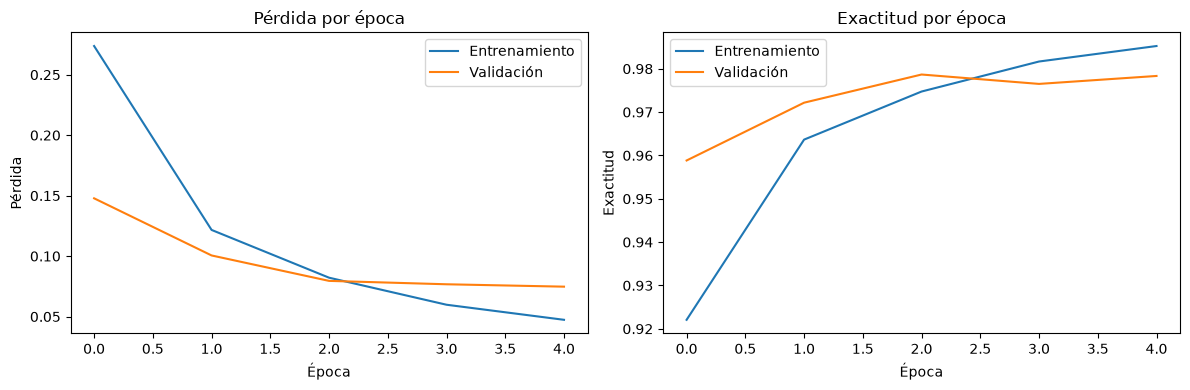

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(historial.history["loss"], label="Entrenamiento")
plt.plot(historial.history["val_loss"], label="Validación")
plt.title("Pérdida por época")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(historial.history["accuracy"], label="Entrenamiento")
plt.plot(historial.history["val_accuracy"], label="Validación")
plt.title("Exactitud por época")
plt.xlabel("Época")
plt.ylabel("Exactitud")
plt.legend()

plt.tight_layout()
plt.show()


## 9. Evaluar con las imágenes de prueba

El conjunto de prueba se mantuvo separado durante el entrenamiento. Evaluarlo al final permite estimar el desempeño con imágenes que no se usaron para aprender ni para supervisar el ajuste. La pérdida resume el error y la exactitud indica la proporción de imágenes clasificadas correctamente. El resultado puede variar ligeramente entre ejecuciones.


In [11]:
perdida_prueba, exactitud_prueba = modelo.evaluate(
    x_test_norm,
    y_test,
    verbose=0
)

print(f"Pérdida en prueba: {perdida_prueba:.4f}")
print(f"Exactitud en prueba: {exactitud_prueba:.4f}")
print(f"Exactitud porcentual: {exactitud_prueba * 100:.2f}%")


Pérdida en prueba: 0.0720
Exactitud en prueba: 0.9767
Exactitud porcentual: 97.67%


## 10. Realizar predicciones

El modelo devuelve diez probabilidades por imagen. `argmax` encuentra el índice de la probabilidad más alta; ese índice se interpreta como el dígito predicho. Compararemos diez imágenes del conjunto de prueba con sus etiquetas reales.


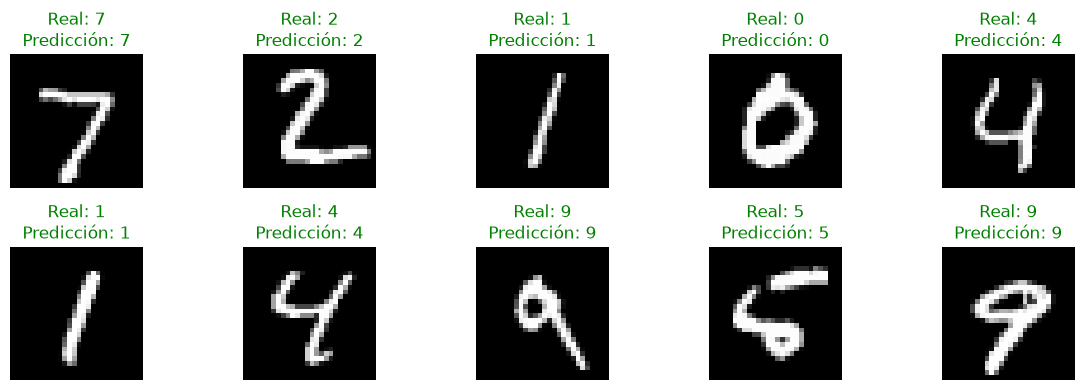

Etiquetas reales: [7 2 1 0 4 1 4 9 5 9]
Predicciones:     [7 2 1 0 4 1 4 9 5 9]


In [12]:
probabilidades = modelo.predict(x_test_norm[:10], verbose=0)
predicciones = np.argmax(probabilidades, axis=1)

plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    color_titulo = "green" if predicciones[i] == y_test[i] else "red"
    plt.title(
        f"Real: {y_test[i]}\nPredicción: {predicciones[i]}",
        color=color_titulo
    )
    plt.axis("off")

plt.tight_layout()
plt.show()
print("Etiquetas reales:", y_test[:10])
print("Predicciones:    ", predicciones)



## 11. Examinar clasificaciones incorrectas

La exactitud global no explica por sí sola qué errores comete el modelo. Aquí evaluaremos las imágenes de prueba y mostraremos hasta diez casos en los que la predicción no coincide con la etiqueta real.


Cantidad de errores: 233


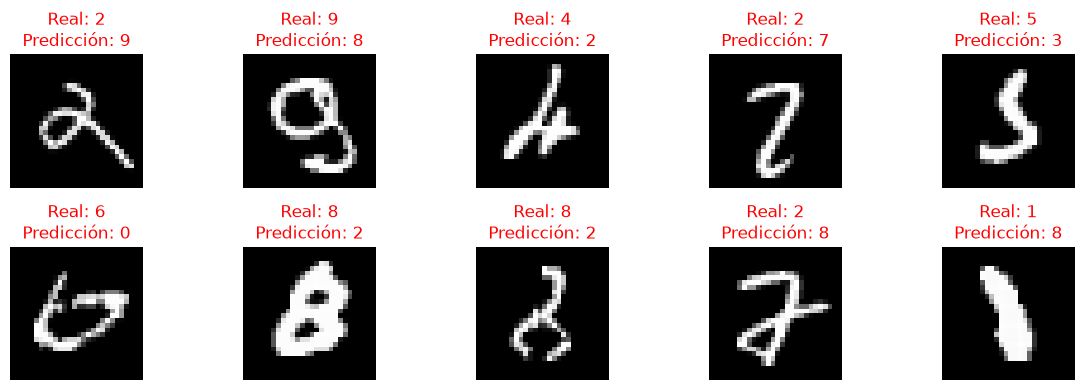

In [13]:
probabilidades_test = modelo.predict(x_test_norm, batch_size=256, verbose=0)
predicciones_test = np.argmax(probabilidades_test, axis=1)
indices_error = np.where(predicciones_test != y_test)[0]

print("Cantidad de errores:", len(indices_error))

if len(indices_error) > 0:
    indices_mostrar = indices_error[:10]
    plt.figure(figsize=(12, 4))
    for posicion, indice in enumerate(indices_mostrar):
        plt.subplot(2, 5, posicion + 1)
        plt.imshow(x_test[indice], cmap="gray")
        plt.title(
            f"Real: {y_test[indice]}\nPredicción: {predicciones_test[indice]}",
            color="red"
        )
        plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron errores en el conjunto de prueba.")


## 12. Actividad de análisis

Responde con tus propias palabras, utilizando los resultados de tu ejecución.

1. ¿Qué representan las dimensiones `(60000, 28, 28)`?
2. ¿Por qué normalizamos los píxeles y qué valores pueden tomar después?
3. ¿Qué transformación realiza `Flatten()` y por qué se necesitan 784 valores?
4. ¿Qué función cumple la capa oculta con 128 neuronas y ReLU?
5. ¿Qué representa cada una de las diez salidas de Softmax?
6. Explica la diferencia entre función de pérdida y exactitud.
7. ¿Qué significa una época de entrenamiento?
8. ¿Por qué separamos una parte de los datos para validación?
9. ¿Por qué reservamos el conjunto de prueba para la evaluación final?
10. ¿Qué observas en las gráficas? ¿Hay señales posibles de sobreajuste?
11. Examina un error de clasificación. ¿Qué características visuales podrían dificultar la clasificación?
12. Propón una modificación (por ejemplo, cambiar el número de neuronas o de épocas) y explica qué resultado esperarías.

## Conclusión

Redacta un párrafo que explique cómo participan los datos, la arquitectura, la función de pérdida, el optimizador y la evaluación en la construcción de una red neuronal. Incluye la exactitud obtenida y una limitación del modelo.

**Criterio importante:** una exactitud alta en MNIST no significa que el modelo reconocerá perfectamente cualquier escritura manuscrita del mundo real. Su desempeño depende de los datos con los que fue entrenado y evaluado.


In [14]:
from PIL import Image

imagen = Image.open("digito5.png").convert("L")

plt.imshow(imagen, cmap="gray")
plt.axis("off")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'digito5.png'

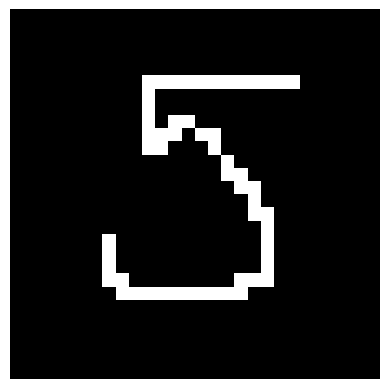

Dígito reconocido: 5
Confianza del modelo: 73.95%


In [62]:
# Redimensionar a 28 x 28 píxeles
imagen = imagen.resize((28, 28))

# Convertir a un arreglo de NumPy
digito = np.array(imagen)

# MNIST espera fondo claro y dígito oscuro.
# Si la imagen tiene fondo negro y letra blanca, se invierten los colores.
#digito = 255 - digito

# Normalizar los valores al intervalo [0, 1]
digito = digito.astype("float32") / 255.0

# Mostrar la imagen preparada
plt.imshow(digito, cmap="gray")
plt.axis("off")
plt.show()

# Preparar la entrada para la red neuronal
entrada = digito.reshape(1, 28, 28)

# Realizar la predicción
prediccion = modelo.predict(entrada, verbose=0)

# Mostrar el dígito con mayor probabilidad
numero = np.argmax(prediccion[0])
confianza = np.max(prediccion[0]) * 100

print("Dígito reconocido:", numero)
print(f"Confianza del modelo: {confianza:.2f}%")

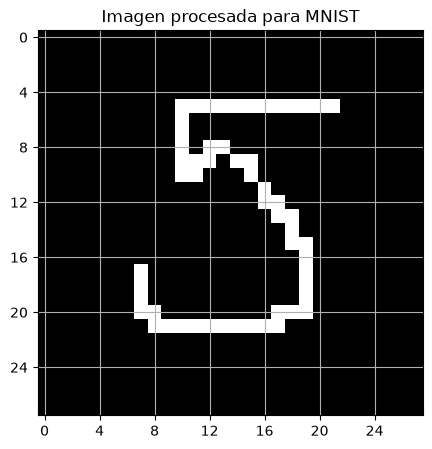

In [63]:
plt.figure(figsize=(5, 5))
plt.imshow(digito, cmap="gray", vmin=0, vmax=1)
plt.title("Imagen procesada para MNIST")
plt.xticks(range(0, 28, 4))
plt.yticks(range(0, 28, 4))
plt.grid()
plt.show()